<a href="https://colab.research.google.com/github/vedrode2011-collab/TFIM-trotter-experiment/blob/main/Quantum_Adder.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister

def quantum_adder(a_str, b_str):
    # Pad to equal length
    n = max(len(a_str), len(b_str))
    a_str, b_str = a_str.zfill(n), b_str.zfill(n)

    a = QuantumRegister(n, 'a')
    b = QuantumRegister(n, 'b')        # will hold the sum
    c = QuantumRegister(n + 1, 'c')    # carries (c[n] = final carry-out)
    out = ClassicalRegister(n + 1, 'out')
    qc = QuantumCircuit(a, b, c, out)

    # Load inputs (string's last char = least significant bit = qubit 0)
    for i, bit in enumerate(reversed(a_str)):
        if bit == '1': qc.x(a[i])
    for i, bit in enumerate(reversed(b_str)):
        if bit == '1': qc.x(b[i])
    qc.barrier()

    def carry(i):
        qc.ccx(a[i], b[i], c[i + 1])
        qc.cx(a[i], b[i])
        qc.ccx(c[i], b[i], c[i + 1])

    def carry_inv(i):
        qc.ccx(c[i], b[i], c[i + 1])
        qc.cx(a[i], b[i])
        qc.ccx(a[i], b[i], c[i + 1])

    def sum_(i):
        qc.cx(a[i], b[i])
        qc.cx(c[i], b[i])

    # Ripple-carry adder (Vedral-Barenco-Ekert)
    for i in range(n):
        carry(i)
    qc.cx(a[n - 1], b[n - 1])
    sum_(n - 1)
    for i in range(n - 2, -1, -1):
        carry_inv(i)
        sum_(i)
    qc.barrier()

    # Measure sum bits + final carry
    for i in range(n):
        qc.measure(b[i], out[i])
    qc.measure(c[n], out[n])

    display(qc.draw('mpl'))
    return qc

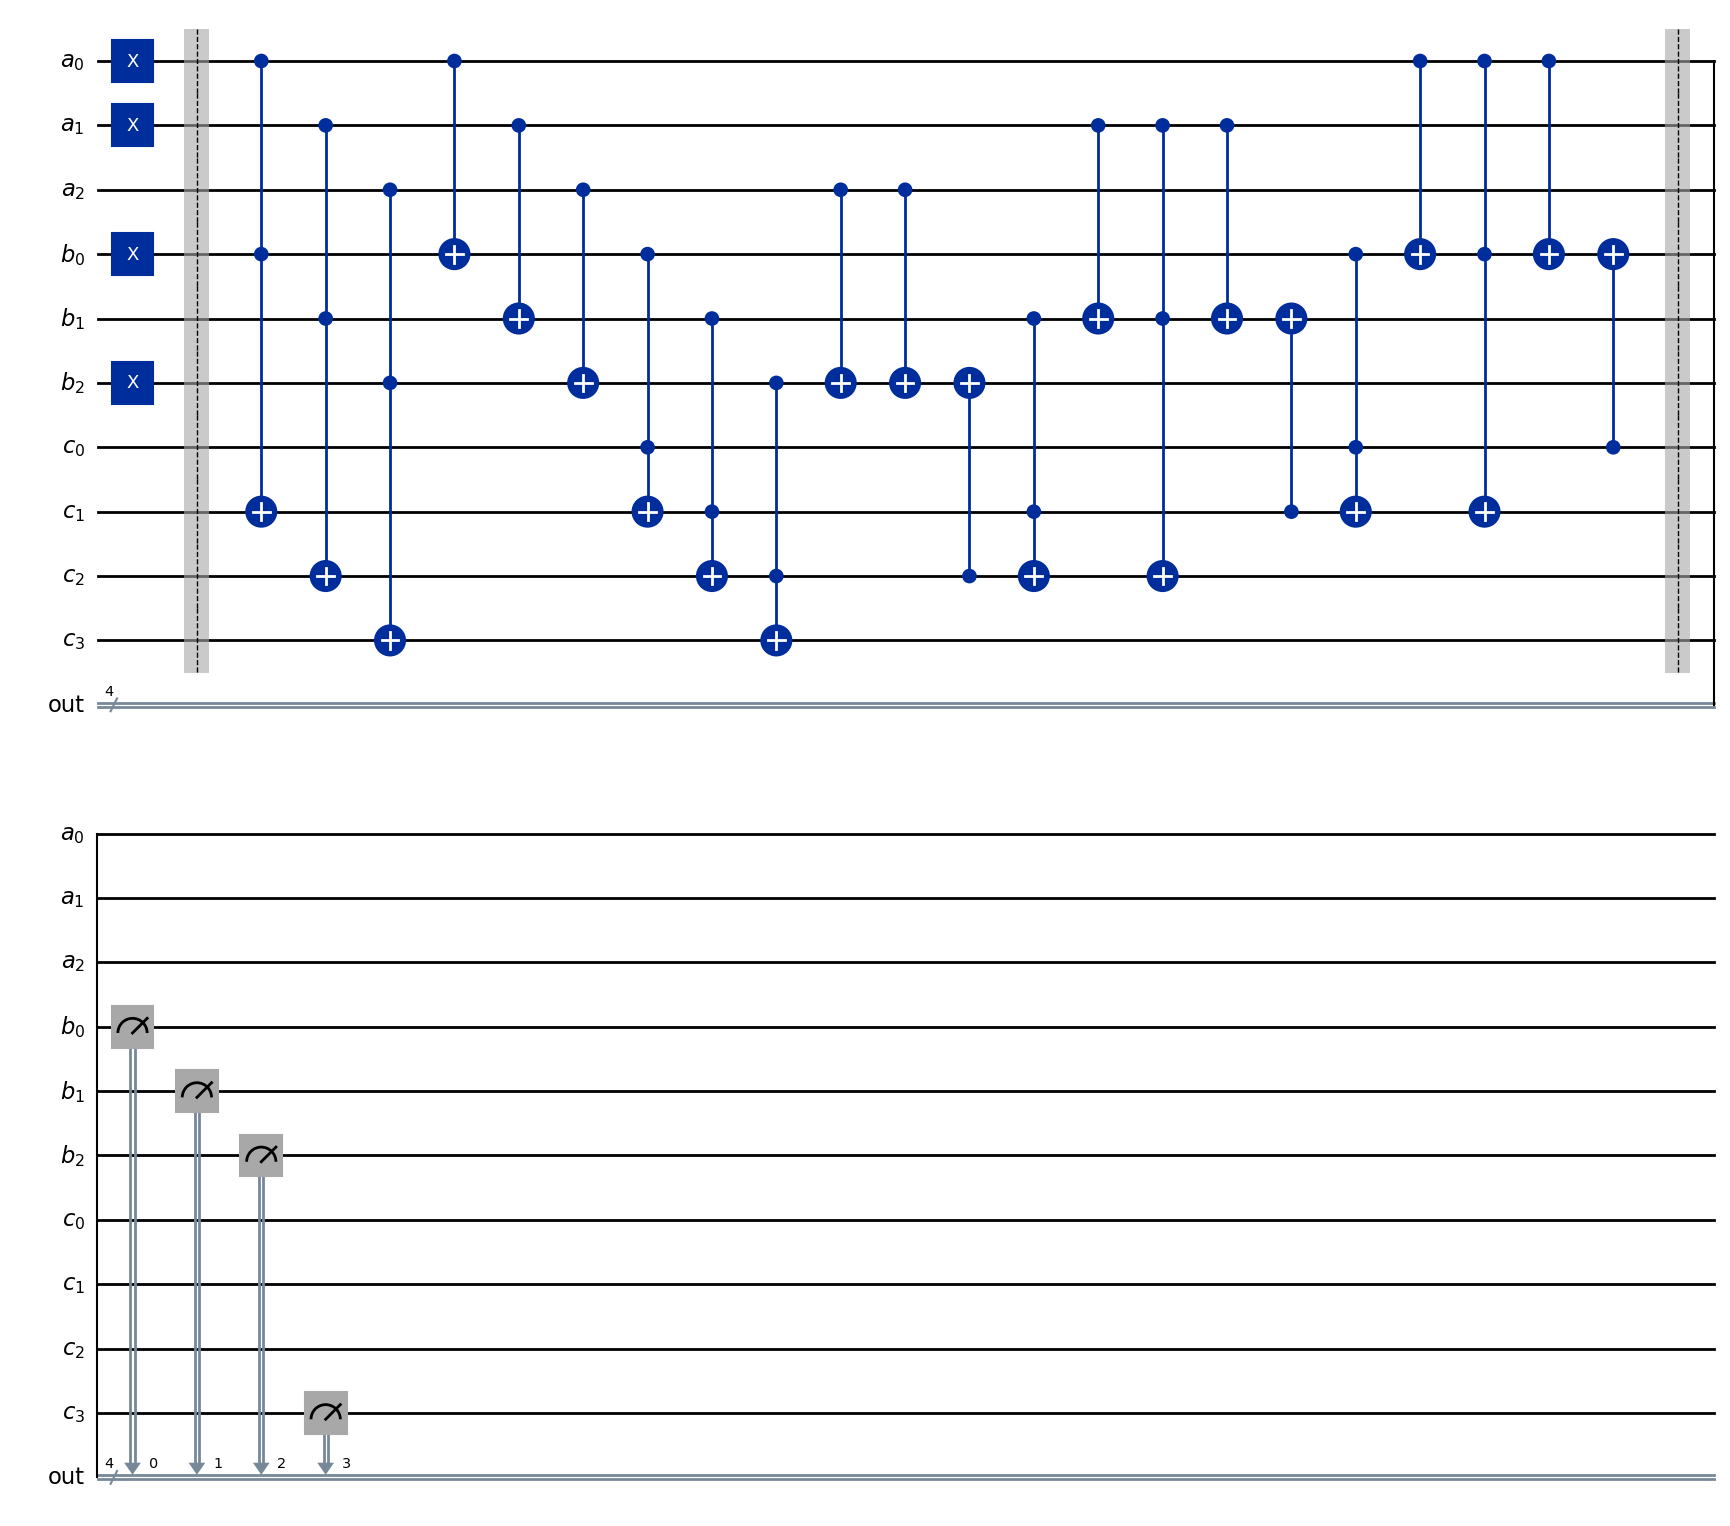

011 + 101 = 1000
3 + 5 = 8


In [ ]:
from qiskit_aer import AerSimulator

A, B = "011", "101"
qc = quantum_adder(A, B)

sim = AerSimulator()
counts = sim.run(qc, shots=1024).result().get_counts()
result = max(counts, key=counts.get)

print(f"{A} + {B} = {result}")
print(f"{int(A, 2)} + {int(B, 2)} = {int(result, 2)}")